In [1]:
import numpy as np
import pandas as pd
import geopandas as gpd

In [2]:
RAW = '../data/raw/'
PROCESSED = '../data/processed/'

estaciones_raw = RAW + 'metadata_estaciones.json'
estados_raw = RAW + 'US_StateBoundaries.geojson'

# Lista con las abreviaturas tal como aparecen en el mapa
estados_central_abrev = [
    "ND", "SD", "NE", "KS", "OK", "TX",
    "MN", "IA", "MO", "AR", "LA",
    "WI", "IL", "MI", "IN"
]

# Lista con los nombres completos en inglés
estados_central_nombres = [
    "North Dakota", "South Dakota", "Nebraska", "Kansas", "Oklahoma", "Texas",
    "Minnesota", "Iowa", "Missouri", "Arkansas", "Louisiana",
    "Wisconsin", "Illinois", "Michigan", "Indiana"
]

## 1. Carga de datos

In [3]:
estaciones = pd.read_json(estaciones_raw)
estados = gpd.read_file(estados_raw)

print(f'Estaciones: {estaciones.shape[0]} filas, {estaciones.shape[1]} columnas')
print(f'Estados (polígonos): {estados.shape[0]} filas - CRS {estados.crs}')
estaciones.head()

Estaciones: 500 filas, 12 columnas
Estados (polígonos): 53 filas - CRS EPSG:4326


,id,elevation,nombre,county,forecast,fireWeatherZone,estado,timeZone,provider,subProvider,longitud,latitud
0,001CE,14.0208,83 Crosby,https://api.weather.gov/zones/county/TXC201,https://api.weather.gov/zones/forecast/TXZ213,https://api.weather.gov/zones/fire/TXZ213,TX,America/Chicago,MesoWest,CENTERPOINT,-95.06369,29.90320
1,002CE,9.7536,62 Baytown,https://api.weather.gov/zones/county/TXC201,https://api.weather.gov/zones/forecast/TXZ313,https://api.weather.gov/zones/fire/TXZ313,TX,America/Chicago,MesoWest,CENTERPOINT,-94.96404,29.80055
2,003CE,10.6680,99 Old River,https://api.weather.gov/zones/county/TXC071,https://api.weather.gov/zones/forecast/TXZ214,https://api.weather.gov/zones/fire/TXZ214,TX,America/Chicago,MesoWest,CENTERPOINT,-94.83204,29.86744
3,004CE,10.9728,100 Channelview N,https://api.weather.gov/zones/county/TXC201,https://api.weather.gov/zones/forecast/TXZ313,https://api.weather.gov/zones/fire/TXZ313,TX,America/Chicago,MesoWest,CENTERPOINT,-95.12692,29.81989
4,004HC,13.1064,3010 SH 288 at MacGregor,https://api.weather.gov/zones/county/TXC201,https://api.weather.gov/zones/forecast/TXZ213,https://api.weather.gov/zones/fire/TXZ213,TX,America/Chicago,MesoWest,HCFCD,-95.37936,29.71302


## 2. Filtrado de los estados de la región central

In [4]:
estados_central = (
    estados[estados['STATE_ABBR'].isin(estados_central_abrev)]
    [['NAME', 'STATE_ABBR', 'geometry']]
    .rename(columns={'NAME': 'nombre_estado', 'STATE_ABBR': 'estado'})
    .reset_index(drop=True)
)

# Control: que estén los 15 estados de la lista
faltantes = set(estados_central_abrev) - set(estados_central['estado'])
print(f'Estados seleccionados: {len(estados_central)} - faltantes: {faltantes or "ninguno"}')

Estados seleccionados: 15 - faltantes: ninguno


### Estaciones sin estado asignado

Algunas estaciones tienen `estado = "N/A"`. En su mayoría son boyas ubicadas en los Grandes Lagos o en el Golfo de México,
por lo que quedan fuera de los polígonos (que sólo cubren tierra firme). Para no perderlas se les asigna el estado:

1. cuyo polígono contiene al punto, o
2. si cae en el agua, el estado más cercano (distancia calculada en una proyección métrica, EPSG:5070).

Las estaciones que ya traen estado conservan el valor original.

In [5]:
print(estaciones['estado'].value_counts().to_string())

estado
TX     237
AR      48
LA      43
N/A     31
MI      26
IA      16
KS      16
IN      14
OK      14
WI      13
MN      13
MO      10
IL       8
SD       5
NE       5
ND       1


In [6]:
CRS_METRICO = 'EPSG:5070'  # Albers equivalente para EE.UU. contiguo

estaciones_gdf = gpd.GeoDataFrame(
    estaciones,
    geometry=gpd.points_from_xy(estaciones['longitud'], estaciones['latitud']),
    crs='EPSG:4326'
)

sin_estado = estaciones_gdf['estado'].eq('N/A')

# Estado más cercano (distancia 0 si el punto está dentro del polígono)
cercano = gpd.sjoin_nearest(
    estaciones_gdf.loc[sin_estado, ['geometry']].to_crs(CRS_METRICO),
    estados[['STATE_ABBR', 'geometry']].to_crs(CRS_METRICO),
    how='left', distance_col='dist_m'
)
cercano = cercano[~cercano.index.duplicated()]  # por si hay empates

estaciones_gdf['origen_estado'] = 'dato original'
estaciones_gdf.loc[sin_estado, 'estado'] = cercano['STATE_ABBR']
estaciones_gdf.loc[sin_estado, 'origen_estado'] = np.where(
    cercano['dist_m'] == 0, 'polígono', 'estado más cercano (agua)'
)

(estaciones_gdf.loc[sin_estado, ['id', 'nombre', 'estado', 'origen_estado']]
 .assign(dist_km=(cercano['dist_m'] / 1000).round(1)))

,id,nombre,estado,origen_estado,dist_km
13,011CE,51 Bacliff,TX,polígono,0.0
208,1890W,Municipal Yacht Harbor - Lakefront,LA,polígono,0.0
234,45001,MID SUPERIOR- 60NM North Northeast Hancock,MI,estado más cercano (agua),45.3
235,45002,Buoy 45002,MI,estado más cercano (agua),31.4
236,45004,EAST SUPERIOR -70 NM NE Marquette,MI,estado más cercano (agua),65.9
237,45006,WEST SUPERIOR - 30NM NE of Outer Island,WI,estado más cercano (agua),54.0
238,45022,Little Traverse Bay Buoy,MI,estado más cercano (agua),4.1
239,45023,North Entry Buoy,MI,estado más cercano (agua),3.3
240,45024,Ludington Buoy,MI,estado más cercano (agua),6.6
241,45025,South Entry Buoy,MI,estado más cercano (agua),1.5


In [7]:
estaciones_central = (
    estaciones_gdf[estaciones_gdf['estado'].isin(estados_central_abrev)]
    .reset_index(drop=True)
)
print(f'Estaciones en la región central: {len(estaciones_central)} de {len(estaciones_gdf)}')
estaciones_central['origen_estado'].value_counts()

Estaciones en la región central: 500 de 500


origen_estado
dato original                469
estado más cercano (agua)     28
polígono                       3
Name: count, dtype: int64

## 3. Estaciones que no reportan observaciones

En la etapa anterior (TP1) las estaciones se tomaron del listado de api.weather.gov para los 15 estados sin verificar qué medía
cada una. La metadata contiene exactamente las **primeras 500 en orden alfabético de identificador** (de `001CE` a `AS602`), y esa
selección arrastra dos problemas:

- **Sobrerrepresenta las redes con identificadores numéricos**: estaciones hidrológicas (pluviómetros y medidores de nivel de ríos de
  HADS, HCFCD o AUSTIN), boyas de los Grandes Lagos (`45xxx`) y la red urbana CENTERPOINT de Houston, que explica buena parte del
  peso de Texas.
- **Deja afuera las estaciones de aeropuerto (ASOS/AWOS)**, la red principal de observación del Servicio Meteorológico, porque sus
  identificadores empiezan con `K` y quedan después de la posición 500.

Al analizar el dataset consolidado (`relaciones-bivariadas.ipynb`) se encontró que muchas estaciones no tienen ninguna observación.
`ETL/clasificar_estaciones.py` midió la cobertura de cada una y generó `estaciones_sin_meteo.csv` con las 155 que se excluyen:

- **129 `sin_meteo`**: aparecen en el dataset, pero nunca reportan variables meteorológicas (la API publica sus observaciones con
  todos los valores en `null`). Son 71 de HADS y 58 de redes hidrológicas de MesoWest.
- **26 `sin_registros`**: no tienen ninguna fila en el dataset. 22 son boyas de los Grandes Lagos.

Quedan 345 estaciones con observaciones. Las secciones siguientes trabajan sobre ellas.

In [8]:
excluidas = pd.read_csv(PROCESSED + 'estaciones_sin_meteo.csv')

estaciones_central = (
    estaciones_central
    .merge(excluidas[['station_id', 'categoria']], left_on='id', right_on='station_id', how='left')
    .drop(columns='station_id')
)
estaciones_central['categoria'] = estaciones_central['categoria'].fillna('con_datos')
estaciones_central['con_datos'] = estaciones_central['categoria'].eq('con_datos')

estaciones_validas = estaciones_central[estaciones_central['con_datos']].reset_index(drop=True)
print(f'Estaciones con observaciones: {len(estaciones_validas)} de {len(estaciones_central)}')

pd.crosstab(estaciones_central['provider'].replace('', '(sin proveedor)'), estaciones_central['categoria'],
            margins=True, margins_name='Total')

Estaciones con observaciones: 345 de 500


categoria,con_datos,sin_meteo,sin_registros,Total
provider,,,,
(sin proveedor),4,0,22,26
APRSWXNET,69,0,0,69
HADS,6,71,0,77
MARITIME,2,0,0,2
MesoWest,251,58,4,313
NOS-NWLON,1,0,0,1
RAWS,12,0,0,12
Total,345,129,26,500


## 4. Cantidad de estaciones por estado

Se cuentan sólo las estaciones con observaciones. La columna `excluidas` indica cuántas se descartaron en cada estado.

El filtro acentúa el desbalance que traía la selección original. Texas pasa de concentrar el 47,8 % de las estaciones al 53,9 %,
la mayoría en el área de Houston. Michigan pierde 27 de sus 43 estaciones (14 de ellas, boyas de los Grandes Lagos),
Dakota del Sur se queda sin estaciones y Dakota del Norte, Nebraska, Missouri, Kansas y Oklahoma quedan con 5 o menos.
Las conclusiones por zona en esos estados descansan sobre muy pocas estaciones.

In [9]:
area_km2 = estados_central.set_index('estado').to_crs(CRS_METRICO).area / 1e6

excluidas_por_estado = estaciones_central[~estaciones_central['con_datos']].groupby('estado').size()

detalle_estados = (
    estaciones_validas.groupby('estado').size()
    .reindex(estados_central_abrev, fill_value=0)
    .rename('estaciones')
    .to_frame()
    .join(estados_central.set_index('estado')['nombre_estado'])
    .assign(
        excluidas=excluidas_por_estado.reindex(estados_central_abrev, fill_value=0),
        porcentaje=lambda d: (100 * d['estaciones'] / d['estaciones'].sum()).round(1),
        area_miles_km2=(area_km2 / 1000).round(1),
        estaciones_cada_10mil_km2=lambda d: (d['estaciones'] / area_km2 * 1e4).round(2),
    )
    .sort_values('estaciones', ascending=False)
    [['nombre_estado', 'estaciones', 'excluidas', 'porcentaje', 'area_miles_km2', 'estaciones_cada_10mil_km2']]
)
detalle_estados

,nombre_estado,estaciones,excluidas,porcentaje,area_miles_km2,estaciones_cada_10mil_km2
estado,,,,,,
TX,Texas,186,53,53.9,685.7,2.71
LA,Louisiana,38,7,11.0,120.9,3.14
AR,Arkansas,36,12,10.4,137.7,2.61
MI,Michigan,16,27,4.6,150.5,1.06
WI,Wisconsin,12,3,3.5,145.3,0.83
IN,Indiana,11,4,3.2,93.7,1.17
MN,Minnesota,10,6,2.9,218.5,0.46
IL,Illinois,9,3,2.6,145.9,0.62
IA,Iowa,8,8,2.3,145.7,0.55


In [10]:
print(f"Estaciones con observaciones: {detalle_estados['estaciones'].sum()} "
      f"({detalle_estados['excluidas'].sum()} excluidas)")
print(f"Texas concentra el {detalle_estados.loc['TX', 'porcentaje']}% de las estaciones")
detalle_estados['estaciones'].describe().round(1)

Estaciones con observaciones: 345 (155 excluidas)
Texas concentra el 53.9% de las estaciones


count     15.0
mean      23.0
std       46.5
min        0.0
25%        4.5
50%        9.0
75%       14.0
max      186.0
Name: estaciones, dtype: float64

## 5. Ubicación geográfica de las estaciones

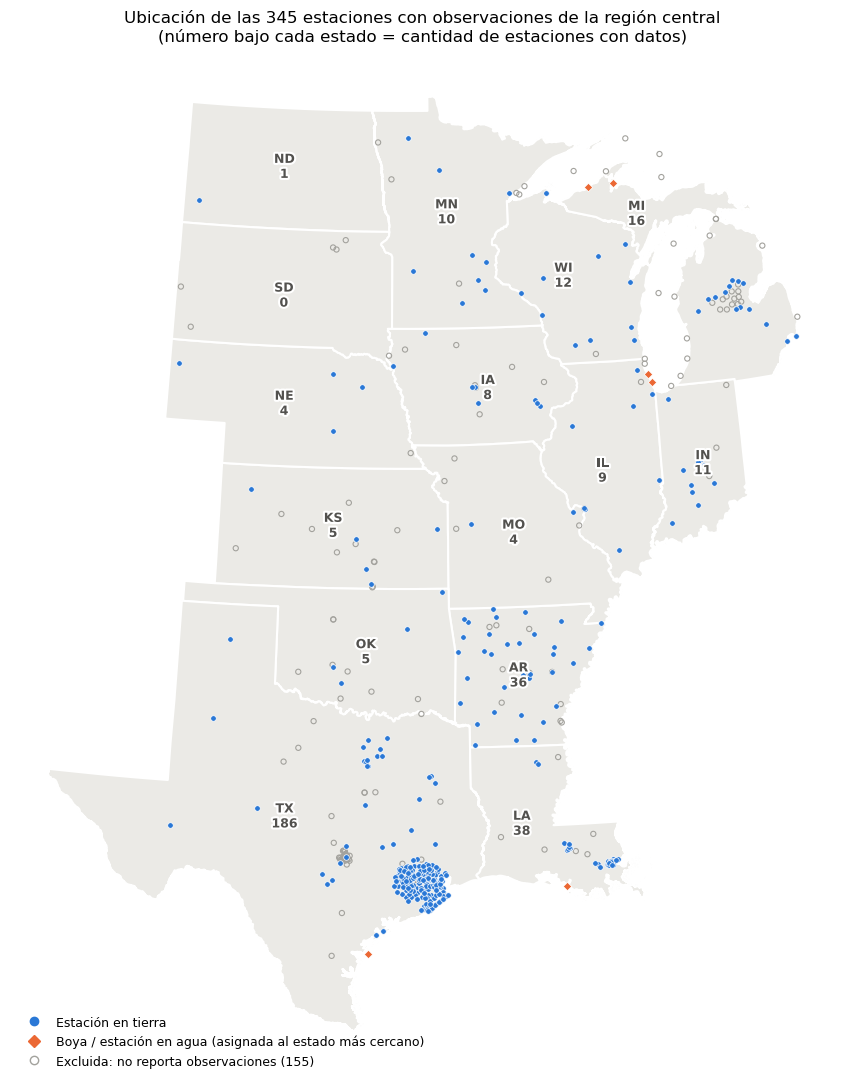

In [11]:
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
import matplotlib.patheffects as pe

estados_plot = estados_central.to_crs(CRS_METRICO)
estaciones_plot = estaciones_validas.to_crs(CRS_METRICO)
excluidas_plot = estaciones_central[~estaciones_central['con_datos']].to_crs(CRS_METRICO)
en_agua = estaciones_plot['origen_estado'].eq('estado más cercano (agua)')

AZUL, NARANJA, GRIS = '#2a78d6', '#eb6834', '#a3a29d'

fig, ax = plt.subplots(figsize=(10, 11))
estados_plot.plot(ax=ax, color='#ebeae6', edgecolor='white', linewidth=1.5)

excluidas_plot.plot(ax=ax, facecolor='none', edgecolor=GRIS, marker='o', markersize=14,
                    linewidth=0.8, zorder=2)

estaciones_plot[~en_agua].plot(ax=ax, color=AZUL, markersize=16,
                               edgecolor='white', linewidth=0.5, zorder=3)
estaciones_plot[en_agua].plot(ax=ax, color=NARANJA, marker='D', markersize=18,
                              edgecolor='white', linewidth=0.5, zorder=3)

# Abreviatura y cantidad de estaciones en cada estado
for _, fila in estados_plot.iterrows():
    p = fila.geometry.representative_point()
    n = detalle_estados.loc[fila['estado'], 'estaciones']
    ax.annotate(f"{fila['estado']}\n{n}", (p.x, p.y), ha='center', va='center',
                fontsize=9, color='#52514e', fontweight='bold', zorder=4,
                path_effects=[pe.withStroke(linewidth=3, foreground='white')])

ax.legend(
    handles=[
        Line2D([], [], marker='o', ls='', color=AZUL, markersize=6, label='Estación en tierra'),
        Line2D([], [], marker='D', ls='', color=NARANJA, markersize=6,
               label='Boya / estación en agua (asignada al estado más cercano)'),
        Line2D([], [], marker='o', ls='', markerfacecolor='none', markeredgecolor=GRIS, markersize=6,
               label=f'Excluida: no reporta observaciones ({len(excluidas_plot)})'),
    ],
    loc='lower left', frameon=False, fontsize=9
)
ax.set_title(f'Ubicación de las {len(estaciones_plot)} estaciones con observaciones de la región central\n'
             '(número bajo cada estado = cantidad de estaciones con datos)', fontsize=12, loc='center')
ax.set_axis_off()
plt.tight_layout()
plt.show()

## 6. Guardado de los datos filtrados

Se guardan las 500 estaciones con las columnas `categoria` y `con_datos`. Así los demás notebooks pueden unir los metadatos (por ejemplo, la zona horaria) a todo el dataset y filtrar después.

In [12]:
import os

os.makedirs(PROCESSED, exist_ok=True)

estaciones_central.to_file(PROCESSED + 'estaciones_central.geojson', driver='GeoJSON')
estados_central.to_file(PROCESSED + 'estados_central.geojson', driver='GeoJSON')

print(f'Guardadas {len(estaciones_central)} estaciones ({estaciones_central["con_datos"].sum()} con observaciones) '
      f'y {len(estados_central)} estados en {PROCESSED}')

Guardadas 500 estaciones (345 con observaciones) y 15 estados en ../data/processed/


## 7. Exportación del mapa y las tablas para la presentación

In [13]:
OUT = '../data/out/'
os.makedirs(OUT, exist_ok=True)

# Mapa: PNG en alta resolución (se pega directo en PowerPoint)
fig.savefig(OUT + 'mapa_estaciones.png', dpi=300, bbox_inches='tight', facecolor='white')

# Tablas con encabezados listos para presentar
tabla_estados = (
    detalle_estados.reset_index()
    .rename(columns={
        'estado': 'Abrev.', 'nombre_estado': 'Estado', 'estaciones': 'Estaciones',
        'excluidas': 'Excluidas', 'porcentaje': '%', 'area_miles_km2': 'Área (miles km²)',
        'estaciones_cada_10mil_km2': 'Estaciones / 10.000 km²',
    })
)
tabla_estados = pd.concat([
    tabla_estados,
    pd.DataFrame([{'Abrev.': '', 'Estado': 'Total', 'Estaciones': tabla_estados['Estaciones'].sum(),
                   'Excluidas': tabla_estados['Excluidas'].sum(), '%': 100.0, 'Área (miles km²)': tabla_estados['Área (miles km²)'].sum().round(1),
                   'Estaciones / 10.000 km²': round(tabla_estados['Estaciones'].sum() / area_km2.sum() * 1e4, 2)}]),
], ignore_index=True)

tabla_reasignadas = (
    estaciones_gdf.loc[sin_estado, ['id', 'nombre', 'estado', 'origen_estado']]
    .assign(dist_km=(cercano['dist_m'] / 1000).round(1),
            con_datos=lambda d: np.where(d['id'].isin(excluidas['station_id']), 'No', 'Sí'))
    .rename(columns={'id': 'ID', 'nombre': 'Nombre', 'estado': 'Estado asignado',
                     'origen_estado': 'Criterio', 'dist_km': 'Distancia (km)',
                     'con_datos': 'Reporta observaciones'})
    .replace({'Criterio': {'polígono': 'Dentro del polígono',
                           'estado más cercano (agua)': 'Más cercano (en agua)'}})
)


def tabla_a_png(df, archivo, titulo):
    """Dibuja un DataFrame como tabla y la guarda como PNG."""
    alto_fila = 0.3
    fig_t, ax_t = plt.subplots(figsize=(8, alto_fila * (len(df) + 1) + 0.6))
    ax_t.set_axis_off()
    tabla = ax_t.table(
        cellText=df.astype(str).values, colLabels=df.columns,
        loc='upper center', cellLoc='center',
    )
    tabla.auto_set_font_size(False)
    tabla.set_fontsize(10)
    tabla.scale(1, 1.4)
    tabla.auto_set_column_width(list(range(df.shape[1])))
    for (fila, col), celda in tabla.get_celld().items():
        celda.set_edgecolor('#d9d8d4')
        if fila == 0:
            celda.set_facecolor('#2a78d6')
            celda.set_text_props(color='white', fontweight='bold')
        elif fila % 2 == 0:
            celda.set_facecolor('#f4f4f2')
        if fila > 0 and df.iloc[fila - 1, 1] == 'Total':
            celda.set_text_props(fontweight='bold')
    ax_t.set_title(titulo, fontsize=12, loc='left', pad=8)
    fig_t.savefig(archivo, dpi=300, bbox_inches='tight', facecolor='white')
    plt.close(fig_t)


tabla_a_png(tabla_estados, OUT + 'tabla_estaciones_por_estado.png',
            'Estaciones meteorológicas con observaciones por estado')
tabla_a_png(tabla_reasignadas, OUT + 'tabla_estaciones_reasignadas.png',
            'Estaciones sin estado en los datos originales y estado asignado')

# CSV editables (separador ';' y coma decimal para abrir directo en Excel en español)
for df, nombre in [(tabla_estados, 'tabla_estaciones_por_estado.csv'),
                   (tabla_reasignadas, 'tabla_estaciones_reasignadas.csv')]:
    df.to_csv(OUT + nombre, sep=';', decimal=',', index=False, encoding='utf-8-sig')

sorted(os.listdir(OUT))

['bivariadas',
 'mapa_estaciones.png',
 'tabla_estaciones_por_estado.csv',
 'tabla_estaciones_por_estado.png',
 'tabla_estaciones_reasignadas.csv',
 'tabla_estaciones_reasignadas.png']